# COURSEWORK SPECIFICATION

## COM1011 - Fundamentals of Machine Learning

**Module Leader:** Chico Camargo

**Academic Year:** 2025/26

**Title:** Coursework 2

**Submission deadline:** 1st December at 12:00pm (noon), 2025.

This assessment contributes **70%** of the total module mark and assesses the following intended learning outcomes:

1. Understanding and identifying the compromises and trade-offs that must be made when using a machine learning approach;
2. Analysing problems from a data-centric point of view, choosing among a range of supervised and unsupervised machine learning techniques and using relevant software libraries to solve them
3. Stating the importance and difficulty of establishing machine learning solutions;
4. Using elementary python for implementing machine learning algorithms.
5. Identifying the compromises that must be made when translating theory into practice


__________________________

# What to submit

You are required to submit your assignment **1st December at 12:00pm (noon), 2025**.

Please do all your work in this Jupyter notebook. Make a separate cell for every few lines of code, and use separate cells for text, like this one.
Save your file in the format `COM1011_STUDENTNUMBER.ipynb` and zip it.
For example, if your student number is 12345678, save your coursework as `COM1011_12345678.ipynb`.
Once you have done that, zip the file, producing a file called `COM1011_12345678.zip`. This is the file you will have to upload and submit to ELE.

This assignment will also use additional CSV files. Do not include them in the `COM1011_STUDENTNUMBER.zip` file.

____________________


# Answer template

Please use this notebook for your coursework. Feel free to add more cells for your code and answers, but try to stick to this format. This will make it easier to mark everyone's work fairly.

___________________

_____________________

# Part A – Probability and Bayesian Inference [10 marks]

Consider a simple poker game. Suppose a deck of poker cards contains four suits: Clubs, Spades, Hearts, and Diamonds, with each suit having 8 cards numbered from 1 to 8. So the total number of cards is 32. The card with the number 8 is the largest, while the card with the number 1 is the smallest. Cards of different suits with the same number are considered equal.

(1) Suppose person A fetches a card with the number 3 of Clubs from the deck. Person B then fetches another card from the deck. What is the probability that person B's card is less than person A's card? Explain how you arrived at the answer. [1 mark]

Answer to (1): P(less than 3) = 0.258 (3d.p) 
There are 8 cards in the deck that are lower than 3: 2 of hearts, 2 of clubs, 2 of spades, 2 of diamonds, 1 of hearts, 1 of clubs, 1 of spades and 1 of diamonds. Therfore the probability of having a card less than 3 is 8/31 as 1 card from the deck has already been taken

(2) If you have drawn four cards sequentially from the deck of 32 cards. What is the total probability that the four cards have the same number 3? (1 mark)



Answer to (2): 4/32 * 3/31 * 2/30 * 1/29 = 0.0000278 (3 d.p) At first, there are 4 cards in the deck with a value of 4, thus 4/32. Once one 3 has been taken, the probability of another 3 is now 3/31. The probability of a third 3 is now 2/30 and the last three is now 1/29. 





(3) If you have drawn four cards sequentially from the deck of 32 cards. What is the total probability that the four cards are of Clubs? Explain how you arrived at the answer [1 mark]


Answer to (2): 8/32 * 7/31 * 6/30 * 5/29 = 0.00195. At first there are 8 clubs in the deck, so the probability is 8/32. Then 7/31 as one club has been taken, then 6/30 and then 5/29.

(4) Suppose person A fetches a card with the number 3 of Hearts from the deck. Person B then fetches another card with the number 6 from the deck. What is the probability that person B's card is also of Hearts? Explain how you arrived at the answer by using Bayesian formula. [2 mark]

Answer to (4): P( Heart | 6) = (P(6|H)*P(H))/P(6) = (1/7 * 7/31)/4/31 = 1/4

(5) Suppose person A fetches a card with the number 2 from the deck of 32 cards. Person B then fetches another card with the number 4 from the deck. What is the probability that person B's card and A's card have the same suit? Explain how you arrived at the answer by using Bayesian formula. [2 marks]

Answer to (5): P(Same Suit|4) = (P(4|SS) * P(SS))/P(4) = (1/7 * 7/31)/4/31 = 1/4

(6) Briefly explain how  Naive Bayesian classifier works such as how the conditional probability is computed for both the cases of discrete features and contineous features. [2 marks]

What is the major limitation of Naive Bayesian classifier in practice? [1 mark]

Answer to (6): 

For discrete features, the conditional probability are estimated using frequency counts from the training data.
For continuous features, the Naive Bayes uses a Gaussian distribution

The main disadvantage of this type of classifier is that, a Naive Bayesian classifier assumes that all variables are conditionally independent which is rarely true in real-world practice.


_____________________

# Part B – Clustering and Dimension Reduction [32 marks]

## 1 Implement K-means clustering for fashion-MNIST dataset:

(7) Load the fashion-MNIST test dataset (`t10k-labels-idx1-ubyte.gz` and `t10k-images-idx3-ubyte.gz`), then obtain the image data denoted as `X_test` and the ground truth labels denoted as `y_test`. After that, pre-process `X_test` by scaling the image pixel values to values between 0 and 1. Source code is provided. [0 mark]

[hint: check https://github.com/zalandoresearch/fashion-mnist?tab=readme-ov-file#get-the-data for detailed information about fashion-MNIST dataset]


In [1]:
# answer to (7). You may need to change path for `t10k-labels-idx1-ubyte.gz` and `t10k-images-idx3-ubyte.gz`
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

def load_mnist(path=None, kind='train'):
    import os
    import gzip
    import numpy as np

    labels_path = 'C:/Users/Oliver/Downloads/t10k-labels-idx1-ubyte.gz'

    images_path = 'C:/Users/Oliver/Downloads/t10k-images-idx3-ubyte.gz'

    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8,
                               offset=8)

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8,
                               offset=16).reshape(len(labels), 784)

    return images, labels


X_test, y_test = load_mnist()
X_test = X_test/255

print(np.max(X_test))

print(X_test.shape)
print(y_test.shape)


1.0
(10000, 784)
(10000,)


(8) Obtain all the test images and their (ground-truth) labels for '3','6','7', respectively, and then rearrange the samples and labels in a random order. [1 mark]

[hint: check https://numpy.org/doc/2.2/reference/generated/numpy.isin.html and https://numpy.org/doc/2.1/reference/random/generated/numpy.random.permutation.html]



In [3]:
# answer to (8)

selected_classes = [3, 6, 7]
indices = np.isin(y_test, selected_classes)

X_filtered = X_test[indices]
y_filtered = y_test[indices]
shuffle_idx = np.random.permutation(len(X_filtered))
X_filtered = X_filtered[shuffle_idx]
y_filtered = y_filtered[shuffle_idx]
print(X_filtered.shape)
print(y_filtered.shape)


(3000, 784)
(3000,)


(9) Use PCA with 2 components to visualise the test data samples in (8) with different colors representing different real (i.e., ground-truth) clusters in a 2d plot. In the plot legend, indicate which colours correspond to which digits. You should use three colors for the three labels: '3','6', '7'. [2 marks]

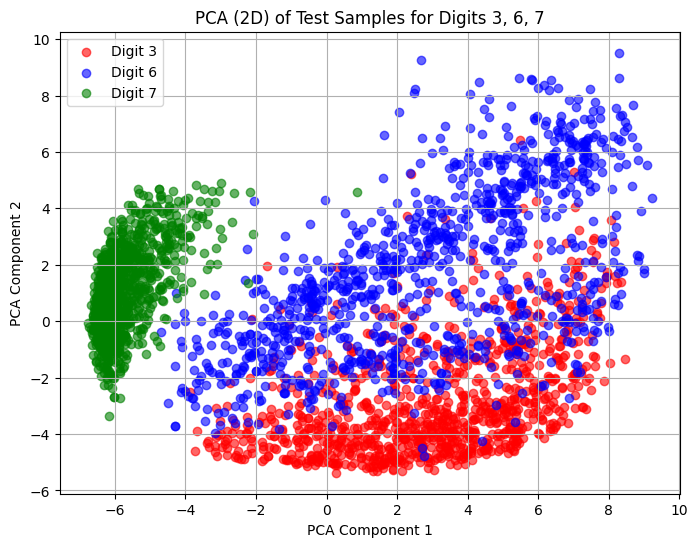

In [4]:
#Answer to (9)
mask = np.isin(y_filtered, [3, 6, 7])

X_test_sel = X_filtered[mask]
y_test_sel = y_filtered[mask]

pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_sel)

color_map = {3: 'red', 6: 'blue', 7: 'green'}

plt.figure(figsize=(8,6))

for digit in [3, 6, 7]:
    idx = y_test_sel == digit
    plt.scatter(X_test_pca[idx, 0], X_test_pca[idx, 1],c=color_map[digit],label=f'Digit {digit}', alpha=0.6)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA (2D) of Test Samples for Digits 3, 6, 7")
plt.legend()
plt.grid(True)
plt.show()

(10) Using the K-means clustering algorithm to cluster the test images in (8) directly, using k=2, 3 and 4. And then use PCA with 2 components to visualize the test data samples with different colors representing different predicted clusters in a 2d plot for each k value. You need to produce three plots, one plot for each k value. [3 marks]


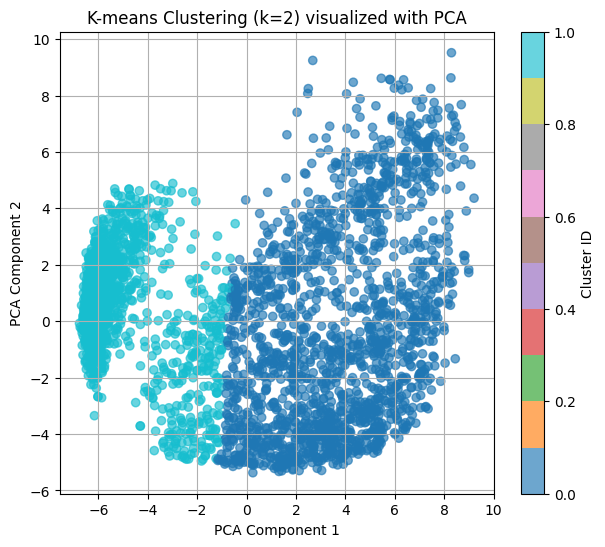

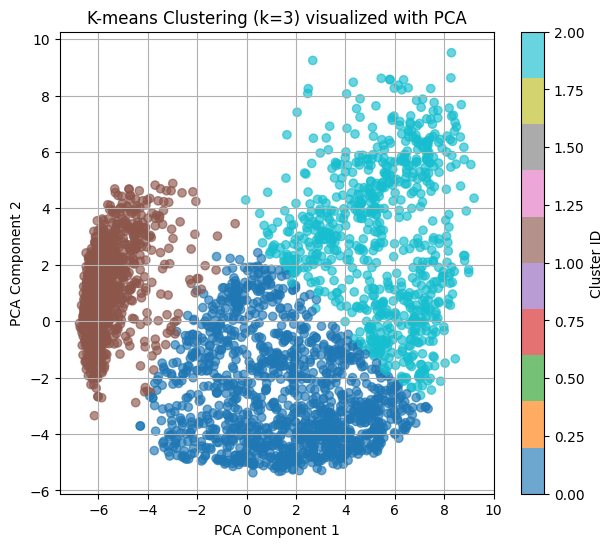

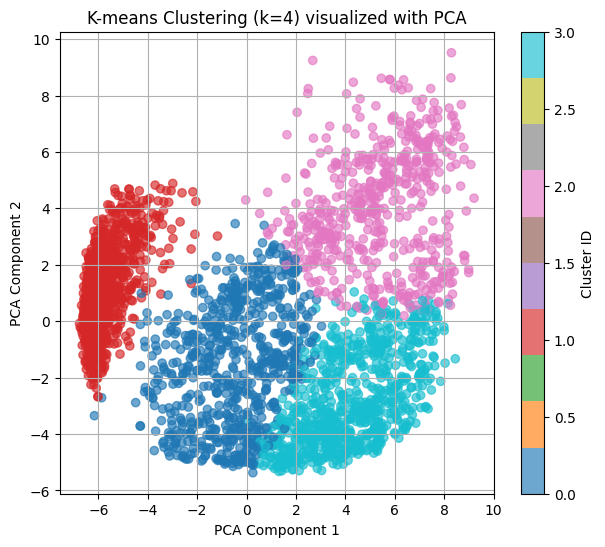

In [5]:
#answer to (10)
from sklearn.metrics import davies_bouldin_score

X_test_sel = X_filtered
y_test_sel = y_filtered
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_test_sel)

def plot_clusters(X_pca, labels, k):
    plt.figure(figsize=(7,6))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', alpha=0.65)
    plt.title(f'K-means Clustering (k={k}) visualized with PCA')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.colorbar(label='Cluster ID')
    plt.grid(True)
    plt.show()


for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=0)
    cluster_labels = kmeans.fit_predict(X_test_sel)
    plot_clusters(X_pca, cluster_labels, k)


(11) Calculate and print the respective Davies-Bouldin scores for k=2,3,4 in (10). Which k value produces the best clustering, according to the Davies-Bouldin score. Then answer: is it consistent with the ground truth number of clusters from fashion-MNIST?   [2 marks]

In [6]:
#answer to (11)
db_score = {}
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=0)
    cluster_labels = kmeans.fit_predict(X_test_sel)
    db = davies_bouldin_score(X_test_sel, cluster_labels)
    db_score[k] = db
    print(f"Davies-Bouldin Score for k={k}: {db}")

best_k = min(db_score, key=db_score.get)
print("Best k according to Davies-Bouldin Score:", best_k)

Davies-Bouldin Score for k=2: 1.392293703671061
Davies-Bouldin Score for k=3: 1.6579349959737641
Davies-Bouldin Score for k=4: 1.5913893666072012
Best k according to Davies-Bouldin Score: 2


continued answer to (11)
This is consistent with the number of clusters from fashion-MNIST as in the plots with 3 and 4 clusters, we can see lots of overlap between the clusters, leading to a higher and worse Davies-Bouldin, however, with 2 clusters, we cannot see much overlap between the two clusters, meaning that the score is consistent with the number of clusters, as 2 has the lowest Davies-Bouldin Score.


 (12) Calculate and print the respective silhouette_scores for k=2,3,4 in (10). Which k value produces the best clustering, according to the Silhouette score. Then answer: is it consistent with the ground truth number of clusters from fashion-MNIST?  [2 marks]

In [7]:
#answer to (12)
sil_score = {}
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=0)
    cluster_labels = kmeans.fit_predict(X_test_sel)
    sil = silhouette_score(X_test_sel, cluster_labels)
    sil_score[k] = sil
    print(f"Silhouette Score for k={k}: {sil:.4f}")


best_sil = max(sil_score, key=sil_score.get)
print("Best Silhoutte Score is:", best_sil)

Silhouette Score for k=2: 0.2753
Silhouette Score for k=3: 0.2401
Silhouette Score for k=4: 0.2238
Best Silhoutte Score is: 2


Continued answer to (12)
The silhouette score is consistent with the plots as when k is 2, we can see well-defined compact plots, however, when k is 3 or 4, there is more overlap between the plots and the plots are bigger and more dispere, resulting in a lower silhouette score. 

(13) Using the K-means clustering algorithm to cluster the first two components of PCA being applied to the tested images, using k=2, 3 and 4. And then compare the clustering results with those from (10) by making of 2 subplots for each value of k: one subplot with the clustering done on the whole images, one sublplot with the clustering done with just the two first components of the PCA. [2 marks]


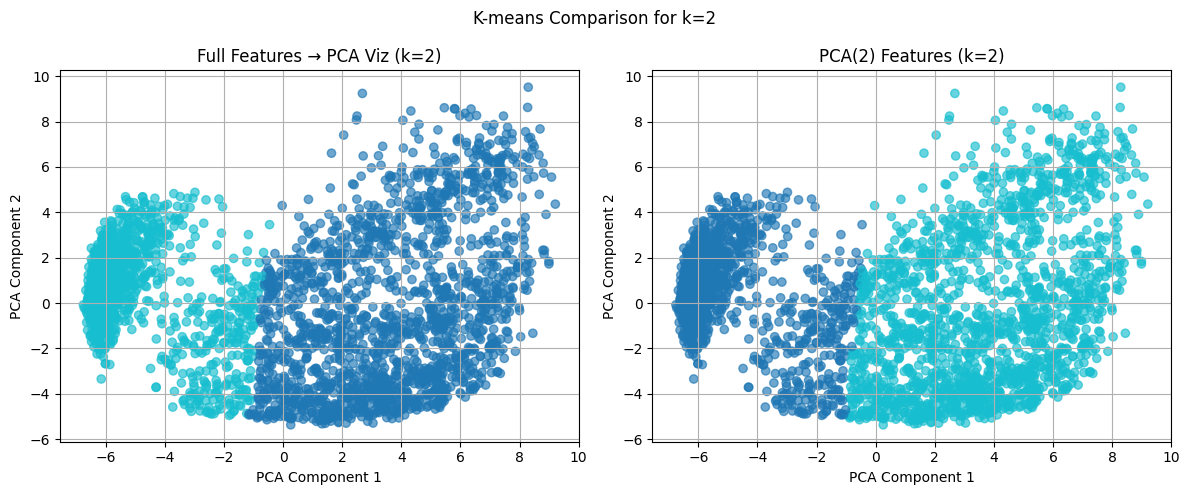

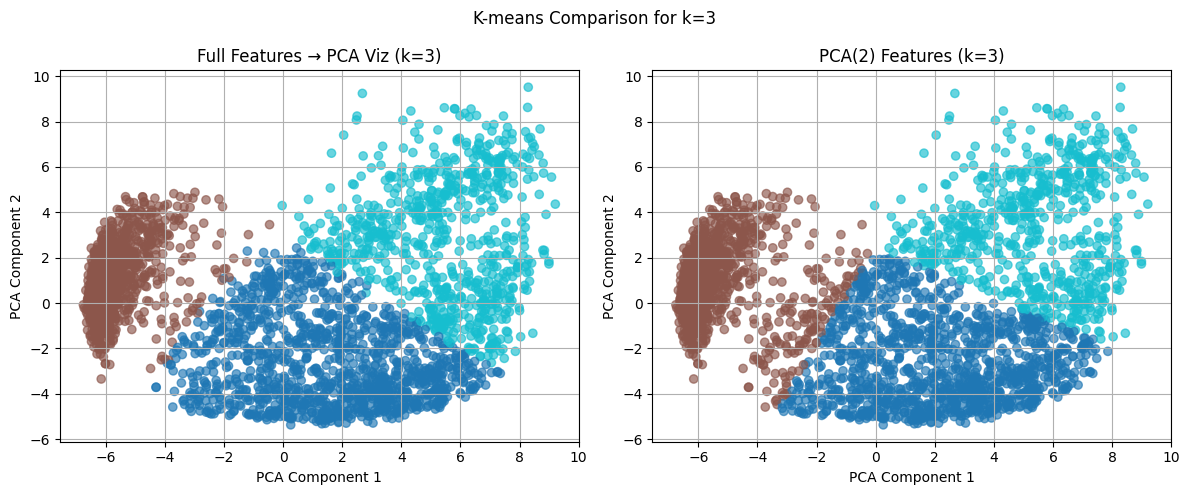

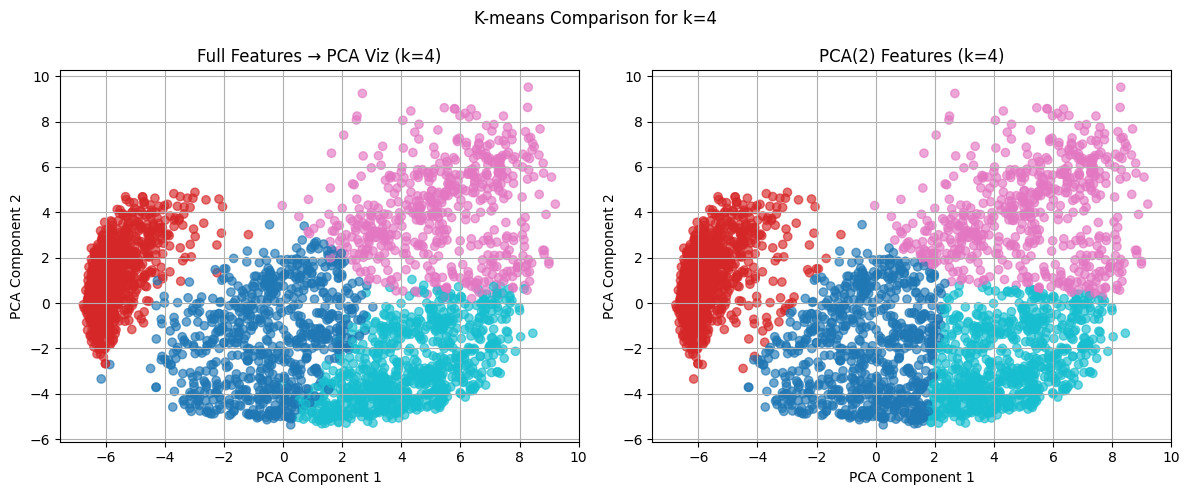

In [8]:
#answer to (13)

pca_2 = PCA(n_components=2)
X_pca2 = pca_2.fit_transform(X_test_sel)

def plot_comparison(X_full_pca, labels_full, X_pca2, labels_pca2, k):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(X_full_pca[:, 0], X_full_pca[:, 1],
                    c=labels_full, cmap='tab10', alpha=0.65)
    axes[0].set_title(f'Full Features → PCA Viz (k={k})')
    axes[0].set_xlabel('PCA Component 1')
    axes[0].set_ylabel('PCA Component 2')
    axes[0].grid(True)

    axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1],
                    c=labels_pca2, cmap='tab10', alpha=0.65)
    axes[1].set_title(f'PCA(2) Features (k={k})')
    axes[1].set_xlabel('PCA Component 1')
    axes[1].set_ylabel('PCA Component 2')
    axes[1].grid(True)

    plt.suptitle(f"K-means Comparison for k={k}")
    plt.tight_layout()
    plt.show()

for k in [2, 3, 4]:

    kmeans_full = KMeans(n_clusters=k, random_state=0)
    labels_full = kmeans_full.fit_predict(X_test_sel)

    kmeans_pca2 = KMeans(n_clusters=k, random_state=0)
    labels_pca2 = kmeans_pca2.fit_predict(X_pca2)

    plot_comparison(X_pca, labels_full, X_pca2, labels_pca2, k)


(14) Compute the Silhouette scores for different k values in (13) and then compare with those obtained in (12). Answer: are the Silhouette scores obtained from the clustering of whole images consistent with the Silhouette scores obtained by clustering only the two first PCA components?  
[2 marks]


In [ ]:
#answer to (14)
from sklearn.metrics import silhouette_score
sil_score = {}
for k in [2, 3, 4]:
    kmeans_full = KMeans(n_clusters=k, random_state=0)
    labels_full = kmeans_full.fit_predict(X_test_sel)
    sil = silhouette_score(X_test_sel, labels_full)
    sil_score[k] = sil
    print(f"Silhouette Score for k={k}: {sil:.4f}")


best_sil = max(sil_score, key=sil_score.get)
print("Best Silhoutte Score is:", best_sil)



Silhouette Score for k=2: 0.2752
Silhouette Score for k=3: 0.2401
Silhouette Score for k=4: 0.2237
Best Silhoutte Score is: 2


Continued answer to (14)
The k value of 2 still remains the best value of k according to the silhouette score which is consistent as it shows the most concise clusters out of all the k value and shows minimal overlap between these clusters.

(15) Let's compare the result of dimensionality reductions by PCA with 2 components and tSNE with 2 components. Apply PCA and tSNE to the test images of '3', '6', and '7', and then visualize the results in 2 subplots, one for each method. Use different colors to represent different real (ground truth) clusters.  [2 marks]  

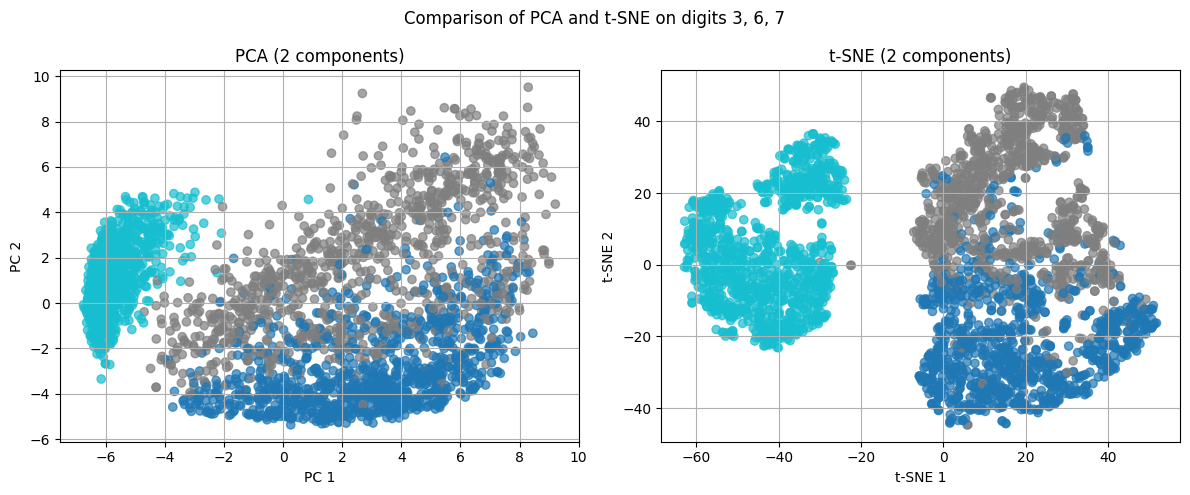

In [9]:
#answer to (15)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

mask = (y_test_sel == 3) | (y_test_sel == 6) | (y_test_sel == 7)
X_3_6_7 = X_test_sel[mask]
y_3_6_7 = y_test_sel[mask]


pca = PCA(n_components=2)
X_pca_2 = pca.fit_transform(X_3_6_7)

tsne = TSNE(n_components=2, perplexity=30, random_state=0)
X_tsne_2 = tsne.fit_transform(X_3_6_7)


plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(X_pca_2[:,0], X_pca_2[:,1], c=y_3_6_7, cmap='tab10', alpha=0.7)
plt.title("PCA (2 components)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.grid(True)

plt.subplot(1,2,2)
plt.scatter(X_tsne_2[:,0], X_tsne_2[:,1], c=y_3_6_7, cmap='tab10', alpha=0.7)
plt.title("t-SNE (2 components)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)

plt.suptitle("Comparison of PCA and t-SNE on digits 3, 6, 7")
plt.tight_layout()
plt.show()



## 2. Implementing DBSCAN clustering for classes of '3', '6', and '7' of fashion-MNIST dataset:


(16) Firstly, use the DBSCAN clustering algorithm to cluster the test images directly by setting the eps parameter to 0.3 and the min_sample to 5. And then apply DBSCAN to cluster the first 2 PCA components of the test images by setting the eps parameter to 0.3 and the min_sample to 5.
Visualize the clustering results in two subplots for each k value and also print out the numbers of estimated clusters. [2 marks]






=== DBSCAN on Full Images ===
Estimated clusters: 0
Noise points: 10000

=== DBSCAN on PCA(2) ===
Estimated clusters: 305
Noise points: 5696


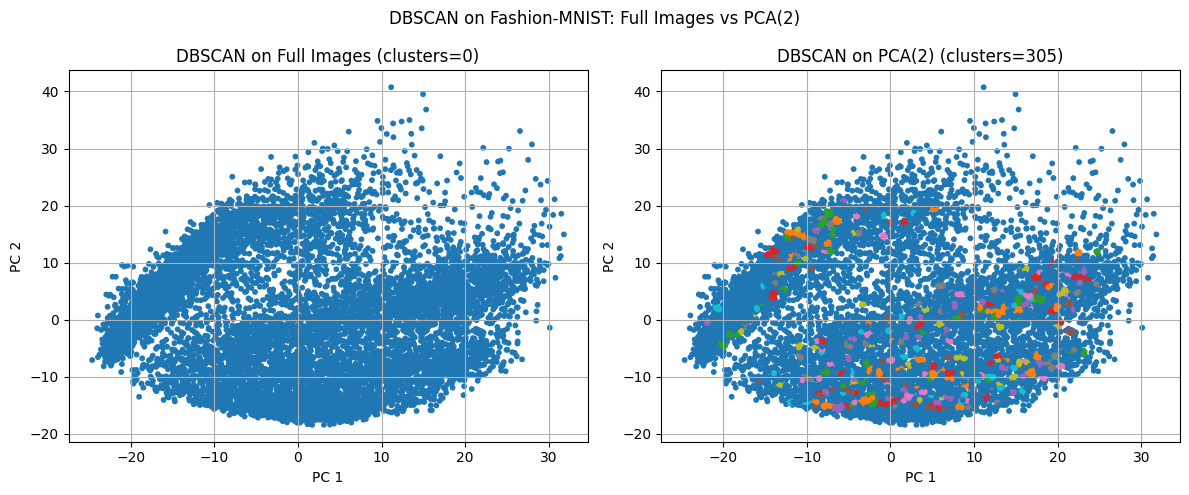

In [10]:
#Answer for (16)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

scaler = StandardScaler()
X_test_scaled = scaler.fit_transform(X_test)


db_full = DBSCAN(eps=0.3, min_samples=5)
labels_full = db_full.fit_predict(X_test_scaled)

n_clusters_full = len(set(labels_full)) - (1 if -1 in labels_full else 0)
n_noise_full = np.sum(labels_full == -1)

print("=== DBSCAN on Full Images ===")
print("Estimated clusters:", n_clusters_full)
print("Noise points:", n_noise_full)

pca = PCA(n_components=2)
X_pca2 = pca.fit_transform(X_test_scaled)


db_pca = DBSCAN(eps=0.3, min_samples=5)
labels_pca = db_pca.fit_predict(X_pca2)

n_clusters_pca = len(set(labels_pca)) - (1 if -1 in labels_pca else 0)
n_noise_pca = np.sum(labels_pca == -1)

print("\n=== DBSCAN on PCA(2) ===")
print("Estimated clusters:", n_clusters_pca)
print("Noise points:", n_noise_pca)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(X_pca2[:,0], X_pca2[:,1], c=labels_full, cmap='tab10', s=10)
plt.title(f"DBSCAN on Full Images (clusters={n_clusters_full})")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.grid(True)

plt.subplot(1,2,2)
plt.scatter(X_pca2[:,0], X_pca2[:,1], c=labels_pca, cmap='tab10', s=10)
plt.title(f"DBSCAN on PCA(2) (clusters={n_clusters_pca})")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.grid(True)

plt.suptitle("DBSCAN on Fashion-MNIST: Full Images vs PCA(2)")
plt.tight_layout()
plt.show()




(17) Changing the eps parameter in (16) to 0.5 and 1, and briefly summarize your observations of the experimental results in terms of the stability of the DBSCAN method in comparison to K-means: is DBSCAN more or less stable than K-means, when it comes to changing hyperparameters? [2 marks]


Answer to (17)

Increasing eps from 0.3 to 0.5 and 1.0 results in different clustering results as the number of clusters decreases sharply and many points switch between noise points and cluster points, and at high eps the data forms into a single cluster. As a result, K-means produces better results when varying k than DBScan.

(18) Compare the performance of K-means and DBSCAN when clustering the data points obtained by applying tSNE with 2 components on test images of classes '3', '6', and '7'.

Set k in K-means to k=3. Play with different values of (eps, min_samples) in DBSCAN to find a proper setup. Visualize the clustering results in 2 subplots. Answer: which method is more robust from the above results? How did you arrive at that conclusion? [2 marks]


Selected samples: 3000
K-Means Results
ARI: 0.7933150703795393
NMI: 0.7836920584005469
DBSCAN Results
ARI: 0.4649768720219153
NMI: 0.6258898317906166
Clusters found: 7
Noise points: 22


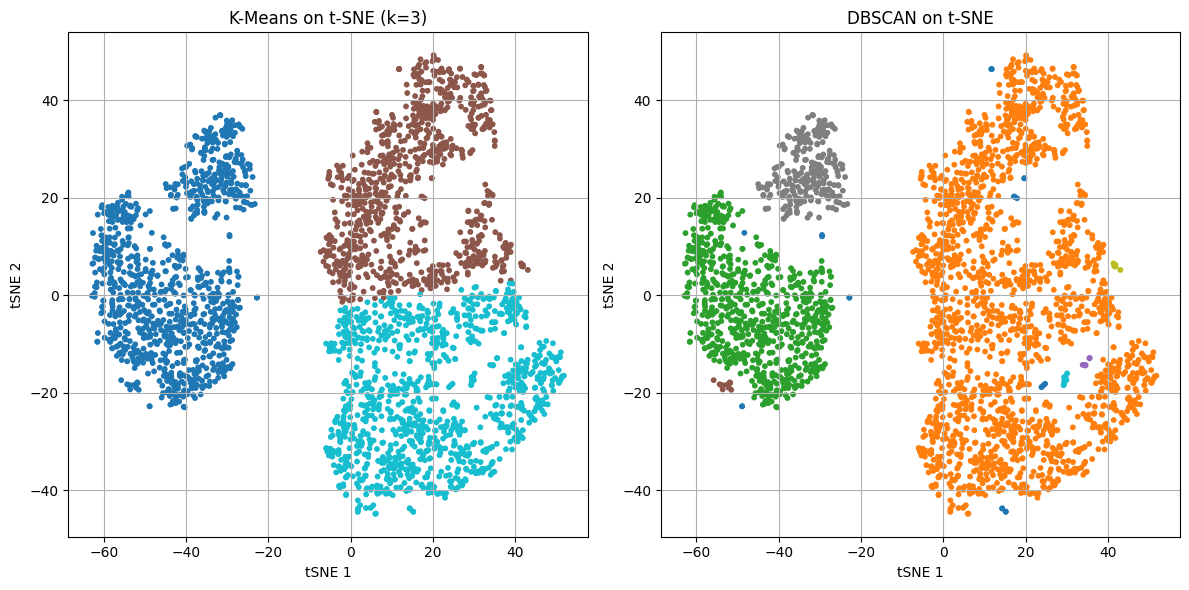

In [11]:
#Answer to (18)
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

classes = [3, 6, 7]
mask = np.isin(y_test, classes)
X_sel = X_test[mask]
y_sel = y_test[mask]

print("Selected samples:", X_sel.shape[0])

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_sel)

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_tsne)

ari_kmeans = adjusted_rand_score(y_sel, kmeans_labels)
nmi_kmeans = normalized_mutual_info_score(y_sel, kmeans_labels)

print("K-Means Results")
print("ARI:", ari_kmeans)
print("NMI:", nmi_kmeans)

db = DBSCAN(eps=3.0, min_samples=5)
db_labels = db.fit_predict(X_tsne)

ari_dbscan = adjusted_rand_score(y_sel, db_labels)
nmi_dbscan = normalized_mutual_info_score(y_sel, db_labels)

print("DBSCAN Results")
print("ARI:", ari_dbscan)
print("NMI:", nmi_dbscan)
print("Clusters found:", len(set(db_labels)) - (1 if -1 in db_labels else 0))
print("Noise points:", np.sum(db_labels == -1))

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=kmeans_labels, cmap='tab10', s=10)
plt.title("K-Means on t-SNE (k=3)")
plt.xlabel("tSNE 1")
plt.ylabel("tSNE 2")
plt.grid(True)

plt.subplot(1,2,2)
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=db_labels, cmap='tab10', s=10)
plt.title("DBSCAN on t-SNE")
plt.xlabel("tSNE 1")
plt.ylabel("tSNE 2")
plt.grid(True)

plt.tight_layout()
plt.show()


Continued answer to (18).
K-means is a more robust model in comparison to DBScan as we can see from the results above. We can see that K-means has an adjusted rand score of 0.793 (3d.p) in comparison to DBScan's score of 0.465 (3 d.p), where the adjusted rand score measures the similarity between two different clusterings of the same set of data points. In addition, we can see that K-means also has a higher normalised mutual info score than DBScan (0.783>0.626) which measures how similar the predicted data points were to the actual data points. From this, we see that K-means is the much better model and is more robust.

(19) Implement bisecting K-means algorithm and Gausian mixture models to cluster the 2 components of tSNE for the test images of classes '3', '6', and '7'. Set the number of clusters to be 3.    [2 marks]

Selected samples: 3000


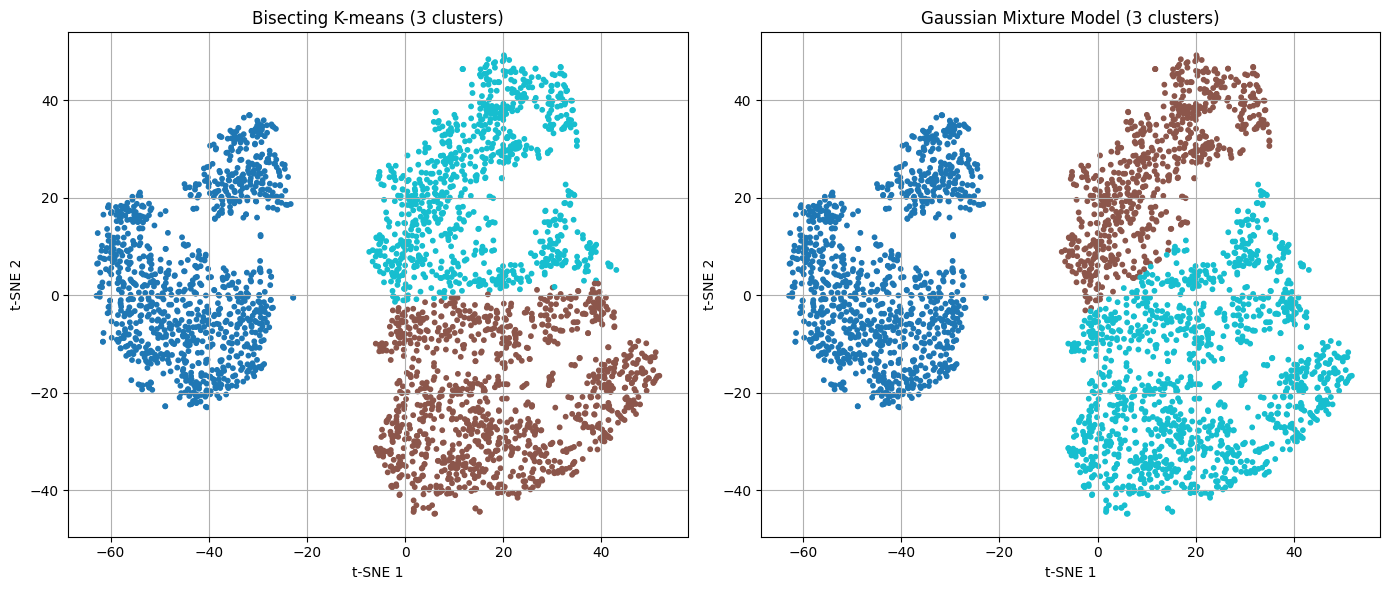

In [13]:
# Answer to (19)
from sklearn.manifold import TSNE
from sklearn.mixture import GaussianMixture
from sklearn.cluster import BisectingKMeans
classes = [3, 6, 7]
mask = np.isin(y_test, classes)
X_sel = X_test[mask]
y_sel = y_test[mask]

print("Selected samples:", X_sel.shape[0])

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_sel)

def bisecting_kmeans(X, K=3, max_iter=10):
    
    clusters = {0: X}  
    
    while len(clusters) < K:
        sse_list = {
            idx: np.sum((data - data.mean(axis=0))**2)
            for idx, data in clusters.items()
        }
        to_split = max(sse_list, key=sse_list.get)
        
        data_to_split = clusters[to_split]
        
        best_labels = None
        best_sse = np.inf
        
        for _ in range(max_iter): 
            km = KMeans(n_clusters=2, random_state=np.random.randint(10000))
            labels = km.fit_predict(data_to_split)
            
            sse_split = sum([
                np.sum((data_to_split[labels == i] - km.cluster_centers_[i])**2)
                for i in range(2)
            ])
            
            if sse_split < best_sse:
                best_sse = sse_split
                best_labels = labels
        
        del clusters[to_split]
        new_ids = sorted(clusters.keys()) + [max(clusters.keys(), default=-1) + 1]
        
        clusters[new_ids[-1]] = data_to_split[best_labels == 0]
        clusters[new_ids[-1] + 1] = data_to_split[best_labels == 1]
    
    final_labels = np.zeros(X.shape[0], dtype=int)
    label_counter = 0
    for idx, data in clusters.items():
        for i in range(len(X)):
            if any((X[i] == row).all() for row in data):
                final_labels[i] = label_counter
        label_counter += 1

    return final_labels



bisect_labels = bisecting_kmeans(X_tsne, K=3)


gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm_labels = gmm.fit_predict(X_tsne)


plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=bisect_labels, cmap='tab10', s=10)
plt.title("Bisecting K-means (3 clusters)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=gmm_labels, cmap='tab10', s=10)
plt.title("Gaussian Mixture Model (3 clusters)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)

plt.tight_layout()
plt.show()



(20). Usually, DBSCAN takes longer than K-means to run, and the time it takes to run is affected by the eps parameter. Explain why that is the case. [4 marks]



Answer to (20)
DBSCAN is slower than K-means because it performs a neighborhood search for every point, which requires far more distance computations and time than K-means which only looks at the centroids. Its depends on the eps parameter because eps determines how many points fall within each point’s neighborhood, meaning that a small eps produces fewer neighbors and can be resolved quicker, while a large eps can cause very large neighborhoods and a massive cluster expansion, increasing the number of distance taking longer. K-means does not depend on neighborhood searches and therefore runs faster and more predictably.


(21). Provide an example of one case in which it might be better to use DBSCAN rather than K-means, and an example of one case in which it might be better to use K-means rather than DBSCAN. Explain why, in both cases. [4 marks]



Answer to (21):
DBScan is a better choice than K-means when the data is not in spherical clusters and irregular. For example, a GPS system for a taxi pickup would benefit DBScan as it can detect arbitraryly shaped clusters such as roads. K-means assumes clusters are spherical and similar in size, so it will incorrectly split long clusters or pull centroids toward outliers.

On the other hand, K-means is a better choice when the data is well-separated and spherical with similar sizes. This is beneficial when doing customer segmentation using demographic features, for example. This is because, K-means performs well when clusters are complex and convex. It is fast and stable when k is known. DBSCAN can fail easily if the correct eps is hard to determine or if densities vary across clusters. 




_____________________

# Part C – Classification and Regression [32 marks]

## 1 Implement a multi-class Logistic Regression classifier for fashion-MNIST dataset.  [20 marks]

(22) Load "train-labels-idx1-ubyte.gz" and "train-images-idx3-ubyte.gz". In the variable X_tmp (see the code below), every row represents a greyscale image, and every one of the 784 columns represent a pixel value. 784 = 28 x 28. So each image is size 28*28.

First, load the two files "train-labels-idx1-ubyte.gz" and "train-images-idx3-ubyte.gz". Then, perform train-test-split to prepare both the training data in terms of (X_train, y_train) and test data in terms of (X_test, y_test). The code for this question is provided below to faciliate the implementation for the following questions. [0 mark]

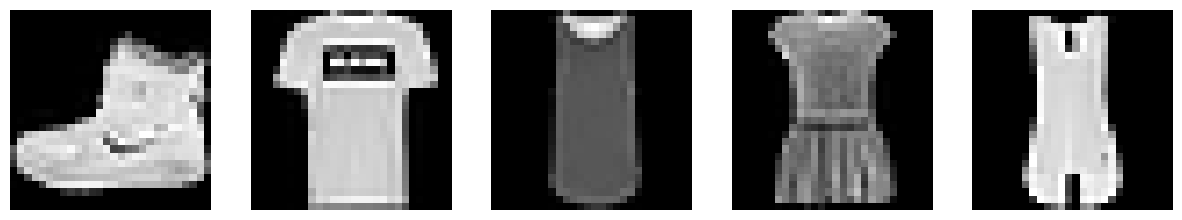

In [14]:
# answer for (22). You may need to change the path for "train-labels-idx1-ubyte.gz" and "train-images-idx3-ubyte.gz".
import pandas as pd
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import numpy as np


def load_mnist(path=None, kind='train'):
    import os
    import gzip
    import numpy as np

    """Load fashion-MNIST data from `path`"""

    labels_path = 'C:/Users/Oliver/Downloads/train-labels-idx1-ubyte.gz'

    images_path = 'C:/Users/Oliver/Downloads/train-images-idx3-ubyte.gz'
    
    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8,
                               offset=8)

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8,
                               offset=16).reshape(len(labels), 784)

    return images, labels


X_tmp, y_tmp = load_mnist()

# normalization
X_tmp = X_tmp/255.0


plt.figure(figsize=(15,3))
for i in range(5):
  image = X_tmp[i,:].reshape(28,28)
  plt.subplot(1, 5, i+1)
  plt.imshow(image, cmap='gray')
  plt.axis('off')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=1)

(23)

Implement a two-class Logistic Regression classifer for classes with labels 4 and 6 in fashion-MNIST by using LogisticRegression from `sklearn.linear_model`. Set random_state to 42, solver='sag' and max_iter=200 in LogisticRegression- (look at the documentation online if needed). Print both the training and test classfication accuracices. [1 mark]

In [15]:
#answer to (23)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
train_mask = (y_train == 4) | (y_train == 6)
test_mask = (y_test == 4) | (y_test == 6)

X_train_fil = X_train[train_mask]
y_train_fil = y_train[train_mask]

X_test_fil = X_test[test_mask]
y_test_fil = y_test[test_mask]

lr=LogisticRegression(random_state=42, solver="sag", max_iter=200)
lr.fit(X_train_fil, y_train_fil)

y_pred_train = lr.predict(X_train_fil)
y_pred_test = lr.predict(X_test_fil)

train_acc = accuracy_score(y_train_fil, y_pred_train)
test_acc  = accuracy_score(y_test_fil, y_pred_test)

print("Training accuracy:", train_acc)
print("Test accuracy:", test_acc)

Training accuracy: 0.9005484839076892
Test accuracy: 0.8818998716302953


C:\Users\Oliver\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


(24) Test solver='sag', random_state=42, and max_iter={300, 500} in (23). Print both the training and test classfication accuracices. [2 marks]

In [18]:
# answer to (24)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
import numpy as np

for it in [300, 500]:
    print("Logistic Regression (max_iter = {it})")

    lr=LogisticRegression(random_state=42, solver="sag", max_iter=it)
    lr.fit(X_train_fil, y_train_fil)

    train_acc = lr.score(X_train_fil, y_train_fil)
    test_acc = lr.score(X_test_fil, y_test_fil)

    print("Training accuracy:", train_acc)
    print("Test accuracy:", test_acc)


Logistic Regression (max_iter = {it})


C:\Users\Oliver\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training accuracy: 0.9009624340266997
Test accuracy: 0.881471972614463
Logistic Regression (max_iter = {it})
Training accuracy: 0.9010659215564525
Test accuracy: 0.881471972614463


(25) Plot both the training and test accuracies for the maximum iterations of 200, 300,  500 being set in LogisticRegression, based on the results from (23) and (24). Put the two curves (one for the training curve and the other for the test curve) in the same 2d plot for easy comparison. Make X axis be the number of maximum iterations (200, 300, 500) and the y axis be the accuracy. [1 mark]

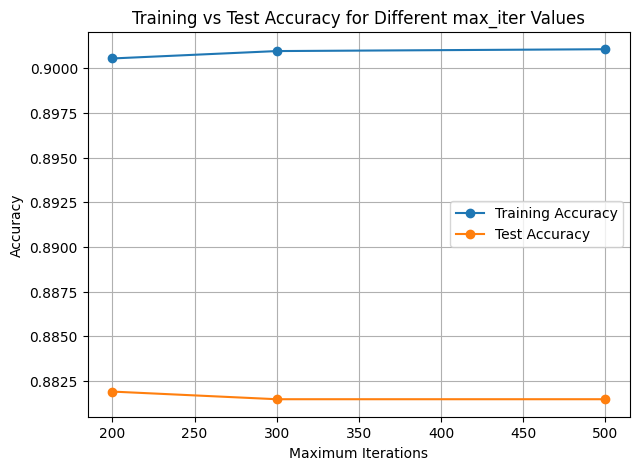

matplotlib.figure.Figure

In [17]:
# Answer to (25)
import matplotlib.pyplot as plt

iters = [200, 300, 500]

train_acc = [
    0.9005484839076892,   
    0.9009624340266997,   
    0.9010659215564525    
]

test_acc = [
    0.8818998716302953,   
    0.881471972614463,    
    0.881471972614463     
]

plt.figure(figsize=(7, 5))
plt.plot(iters, train_acc, marker='o', label='Training Accuracy')
plt.plot(iters, test_acc, marker='o', label='Test Accuracy')

plt.xlabel('Maximum Iterations')
plt.ylabel('Accuracy')
plt.title('Training vs Test Accuracy for Different max_iter Values')
plt.grid(True)
plt.legend()
plt.show()
plt.Figure



(26) Three classification models have been obtained from (23) and (24) by setting different values for the hyper-parameter max_iter. Which model should we choose? Explain why. [1 mark]

What is overfitting? Why is that a problem, and how can one avoid it? [3 marks]

Does the plot in (25) exhibit over-fitting? Explain why. [1 mark]  


Answer to (26):
We should choose the model from question (23) as it shows a slightly better test accuracy than the model in question (24) meaning that it performs better on unseen data, in comparison to the other model.


Overfitting is when a model learns the training data too well instead of learning the underlying patterns within the training data. This is a huge problem as on paper, the model will perform extremly well on the training data, however, once it is applied to a different data set, it will perform terribly. We can avoid overfitting by performing different techniques on the model. For example, we can use feature selection, to select only important features of the dataset and removing irrelevant sections, reducing the chance of the model learning the entire dataset. Furthermore, we can also perfrom cross-validation on the model, to train the model on different subsets of the data, and evaluate its model on the remaining data.

The plot does exhibit over fitting as it shows that the more iterations, there are, the higher the training-accuracy and the lower the test-accuracy, showing that the model will only learn the dataset at some point

(27) Let's do some data augmentation to improve the test performance in (23) and (24). In doing so, prepare additional training data for class 4 and 6 of fashion-MNIST by flipping each image horizontally using a library like numpy.flip. Display one original image alongside its flipped version to demonstrate the augmentation.   [2 marks]

Then, use both the original training data and the flipped training data to train the two-class Logistic Regression classifer. Print out the training and test accuracies for max_iter = {200, 300, 500}.  [2 marks]

Training samples: 9663
Test samples: 2337
Original training shape: (9663, 784)
Augmented training shape: (19326, 28, 28)


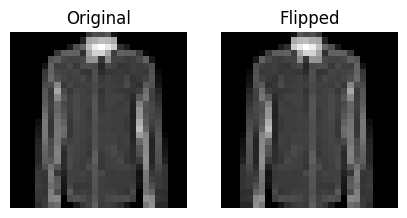

C:\Users\Oliver\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression (max_iter = {m})
Training accuracy: 0.8911311187001967
Test accuracy: 0.8780487804878049


C:\Users\Oliver\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression (max_iter = {m})
Training accuracy: 0.8917520438787127
Test accuracy: 0.8797603765511339
Logistic Regression (max_iter = {m})
Training accuracy: 0.8910276311704439
Test accuracy: 0.8797603765511339


In [20]:
# Answer to (27)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from scipy.ndimage import rotate
import numpy as np
from sklearn.preprocessing import StandardScaler

classes = [4, 6]
train_mask = np.isin(y_train, classes)
test_mask = np.isin(y_test, classes)

X_train_2 = X_train[train_mask]
y_train_2 = y_train[train_mask]
X_test_2 = X_test[test_mask]
y_test_2 = y_test[test_mask]

print("Training samples:", len(X_train_2))
print("Test samples:", len(X_test_2))

print("Original training shape:", X_train_2.shape)

X_train_2_img = X_train_2.reshape(-1, 28, 28)


X_train_flipped = np.flip(X_train_2_img, axis=2)   
y_train_flipped = y_train_2.copy()


X_train_aug = np.concatenate([X_train_2_img, X_train_flipped], axis=0)
y_train_aug = np.concatenate([y_train_2, y_train_flipped], axis=0)

print("Augmented training shape:", X_train_aug.shape)


idx = 0
plt.figure(figsize=(5, 3))

plt.subplot(1, 2, 1)
plt.title("Original")
plt.imshow(X_train_2_img[idx], cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Flipped")
plt.imshow(X_train_flipped[idx], cmap="gray")
plt.axis("off")

plt.show()

X_train_aug_flat = X_train_aug.reshape(len(X_train_aug), -1)
X_test_flat = X_test_2.reshape(len(X_test_2), -1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_aug_flat)
X_test_scaled = scaler.transform(X_test_flat)

iters = [200, 300, 500]

for m in iters:
    clf = LogisticRegression(max_iter=m)
    clf.fit(X_train_scaled, y_train_aug)

    y_train_pred = clf.predict(X_train_scaled)
    y_test_pred = clf.predict(X_test_scaled)

    train_acc = accuracy_score(y_train_aug, y_train_pred)
    test_acc = accuracy_score(y_test_2, y_test_pred)

    print("Logistic Regression (max_iter = {m})")
    print("Training accuracy:", train_acc)
    print("Test accuracy:", test_acc)



(28) In general, is the image-flip technique a reasonable approach for the considered classification problem? Provide your reasoning. [2 marks]

For classes 4 and 6, the image-flip is a reasonable technique as they are both symmetrical so they look like the same class when mirrored. This method is also very efficient as it doesn't take long and increases effective training data when there isn't enough examples in the dataset. 


Is the test accuracy obtained in (27) better than those in (23) and (24)? [1 mark]

No, as the test accuracy in (27) is:
Test accuracy: 0.8797603765511339
whereas the accuracy in (23) is:
Test accuracy: 0.8818998716302953
and the accuracy in (24) is:
Test accuracy: 0.881471972614463
Therefore they both have a higher accuracy of approximately 0.01 more than the accuracy of question (27)



Consider three approaches: 1-change to advanced machine learning models, 2-employ other data augmentation techniques, 3-employ other data pre-processing techniques.  What do you think is the most effective approach to improve the test performance ? Why. [2 marks]

In my opinion, the most effective approach to improve test performance would be to 1, to change to advanced machine learning models as they would be able to perform better on the dataset than logistic regression as logistic regression is limited by being linear.

Elaborate on the most effective approach you have chosen by providing more detailed suggestions. [2 marks]

Using a non-liner classifier such as Random Forest or Gradient Boosting can outperform linear models by capturing non-linear interactions between pixels increasing accuracy by around 3% meaning that it would result in a 90% plus accuracy.

Answer to (28):



## 2 Implement regression for the housing dataset.  [12 marks]

(29) Check how normalization affects the regression performance with the dataset "housing.csv".

Firstly, visualize the correlation matrix in terms of the heat map for all the 14 features. [0.5 mark]

Secondly, implement a Linear model that use only the 'CRIM' and 'RM' to predict 'TAX' without normalization. In doing so, split the data into training and test datasets. Report both the training and test errors in terms of mean squared error (MSE). [0.5 mark]  

Thirdly, do normalization (refer to the operation of scaling each feature to be in the range of [0,1]) to the data, and then implement a Linear model that use normalized 'CRIM' and normalized 'RM' to predict normalized 'TAX'. Report both the training and test errors.  What conclusions can you draw by comparing the above prediction results regarding the impact of normalization? [1 mark]  



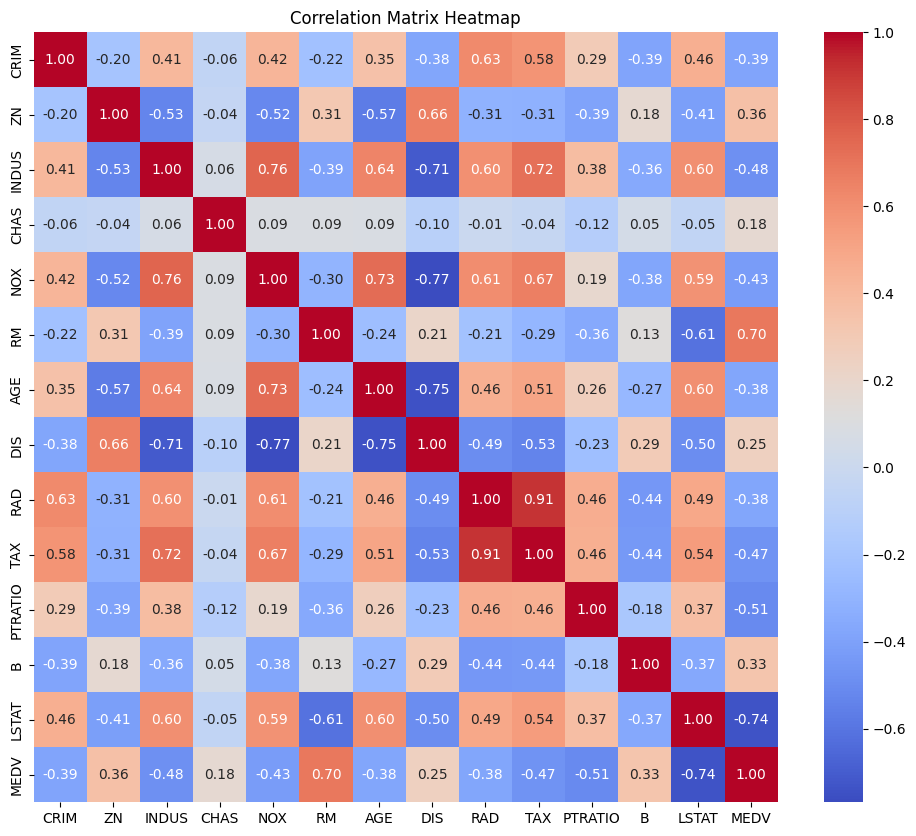

Training MSE: 17591.13361925391
Test MSE: 19360.270507370045
Training MSE (Normalised): 0.6386325176890376
Test MSE (Normalised): 0.7028596658335737


In [21]:
# Answer to (29)
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import math
import pandas as pd
from matplotlib import pyplot as plt

column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE','DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

data = pd.read_csv("C:/Users/Oliver/Downloads/housing.csv")
data = data.astype(float)

corr = data.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

X = data[['CRIM', 'RM']]
y = data['TAX']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


train_mse = mean_squared_error(y_train, y_train_pred)
test_mse  = mean_squared_error(y_test, y_test_pred)

print("Training MSE:", train_mse)
print("Test MSE:", test_mse)

X = data[['CRIM', 'RM']]
y = data['TAX']

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1, 1))

model.fit(X_train_scaled, y_train_scaled)

y_train_pred_scaled = model.predict(X_train_scaled)
y_test_pred_scaled  = model.predict(X_test_scaled)


train_mse = mean_squared_error(y_train_scaled, y_train_pred_scaled)
test_mse  = mean_squared_error(y_test_scaled, y_test_pred_scaled)

print("Training MSE (Normalised):", train_mse)
print("Test MSE (Normalised):", test_mse)


Continued answer to (29): 
Normalisation does not make the linear model more accurate by predicting models, but it makes the model more stable, better behaved, and easier to interpret.

(30) Check how correlation strength affects the regression performance with the dataset "housing.csv".

Use normlized "CRIM" and normalized "ZN" to predict normalized "TAX" by using a linear model. Print out the training and test mean squared error. Remember using the same random_state and the same test_size when running the train_test_split function from sklearn.model_selection.   [1 mark]  

Use normlized "CRIM" and normalized "INDUS" to predict normalized "TAX" by using a linear model. Print out the training and test mean squared error. Remember using the same random_state and the same test_size when running the train_test_split function from sklearn.model_selection.   [1 mark]  





In [22]:
# Answer to (30)
X = data[['CRIM', 'ZN']]
y = data['TAX']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1,1))
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1,1))

model = LinearRegression()
model.fit(X_train_scaled, y_train_scaled)

y_train_pred_scaled = model.predict(X_train_scaled)
y_test_pred_scaled  = model.predict(X_test_scaled)

train_mse = mean_squared_error(y_train_scaled, y_train_pred_scaled)
test_mse  = mean_squared_error(y_test_scaled, y_test_pred_scaled)

print("Training MSE (normalized CRIM & ZN):", train_mse)
print("Test MSE (normalized CRIM & ZN):", test_mse)


Training MSE (normalized CRIM & ZN): 0.6336278511515461
Test MSE (normalized CRIM & ZN): 0.6632403690381252


(31) What conclusions can you draw by comparing the test errors of (29) and (30) regarding the impact of the correlation strength (check the heat map shown above)? [1 mark]

Answer to (31):

The test error in (30) is higher than in (29) because CRIM and INDUS have weaker correlation with TAX, as shown in the heat map. However, the model in (29) used more strongly correlated features, resulting in lower test error.

(32) Convert a regression problem to a classification problem of 10 classes.

First pre-processing the data for "TAX" to be in the range of [0,10) denoted as yy in the data type of float. Then tranform (via the rounding opertion) yy into the data type of integer within {0,1,2,.., 9} denoted as y. [1 mark]

Obtain training and test datasets from  normlized "CRIM", normalized "INDUS", and the ground truth labels y. Then implement a Logistic classifer and report the training and test accuracies.  Set random_state to 42, solver='sag' and max_iter=200 in LogisticRegression. [1 mark]

Rescale the prediced labels from the Logistic classifer to the range of [0, 1] and then compute and print out the mean squqred errors (MSEs) with respect to the normalized ground truth "TAX" for both training and test datasets.  [1 mark]

Compare the obtained MSEs with those in (30). Which method produces lower MSE for test dataset?  Which method produces lower MSE for training dataset? Do you think converting a regression problem to a classification problem is a resonable approch in general? [1 mark]


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_squared_error 
scaler = StandardScaler()
data[["CRIM_n", "INDUS_n", "TAX_n"]] = scaler.fit_transform(
    data[["CRIM", "INDUS", "TAX"]]
)

yy = data["TAX_n"] * 10          
y = yy.round().astype(int)       
y[y == 10] = 9                   

X = data[["CRIM_n", "INDUS_n"]]

X_train, X_test, y_train, y_test, yy_train, yy_test = train_test_split(
    X, y, yy, test_size=0.2, random_state=42
)

clf = LogisticRegression(
    random_state=42,
    solver='sag',
    max_iter=200,
    multi_class='auto'
)

clf.fit(X_train, y_train)

pred_train = clf.predict(X_train)
pred_test  = clf.predict(X_test)


train_acc = accuracy_score(y_train, pred_train)
test_acc  = accuracy_score(y_test, pred_test)

print("Training Accuracy:", train_acc)
print("Test Accuracy:    ", test_acc)

pred_train_scaled = pred_train / 9
pred_test_scaled  = pred_test  / 9

mse_train = mean_squared_error(yy_train / 10, pred_train_scaled)
mse_test  = mean_squared_error(yy_test  / 10, pred_test_scaled)

print("Training MSE:", mse_train)
print("Test MSE:    ", mse_test)




Training Accuracy: 0.45544554455445546
Test Accuracy:     0.45098039215686275
Training MSE: 0.1834101887174522
Test MSE:     0.15743369834502743


C:\Users\Oliver\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Continued answer to (32)




Continued answer to (32)




The test MSE of the model in question (32) is significantly lower (0.15743369834502743) than the test MSE of the model in question (30) (0.6336278511515461) which is the same for the training MSE, where the model in question (32) (0.1834101887174522) has a much lower value than the model in question (33) (0.6632403690381252). I think converting the regression problem into classification problems is a bad approach as information can be lost and therefore resulting in a worse performance in the model

(33) Convert the same regression problem in (32) to a classification problem of 100 classes. Set random_state to 42, solver='sag' and max_iter=200 in LogisticRegression. Report the MSEs for both training and test datasets.  [1 mark]

Compare the obtained MSEs with those of the classification method in (32).
Is the performance get better? [1 mark]

How to futher improve the peformance of the classification method? [1 mark]

In [24]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
data[["CRIM_n", "INDUS_n", "TAX_n"]] = scaler.fit_transform(
    data[["CRIM", "INDUS", "TAX"]]
)

yy = data["TAX_n"] * 10

X = data[["CRIM_n", "INDUS_n"]]

yy_min, yy_max = yy.min(), yy.max()

bins = np.linspace(yy_min, yy_max, 101)

y100 = np.digitize(yy, bins) - 1
y100[y100 == 100] = 99   

X_train, X_test, y_train100, y_test100, yy_train, yy_test = train_test_split(
    X, y100, yy, test_size=0.2, random_state=42
)


clf100 = LogisticRegression(
    random_state=42,
    solver='sag',
    max_iter=200,
    multi_class='multinomial'
)

clf100.fit(X_train, y_train100)

pred_train_cls = clf100.predict(X_train)
pred_test_cls  = clf100.predict(X_test)

bin_midpoints = (bins[:-1] + bins[1:]) / 2

pred_train_cont = bin_midpoints[pred_train_cls]
pred_test_cont  = bin_midpoints[pred_test_cls]

scaler_y = StandardScaler()

yy_train_arr = yy_train.values.reshape(-1, 1)
yy_test_arr  = yy_test.values.reshape(-1, 1)

pred_train_arr = pred_train_cont.reshape(-1, 1)
pred_test_arr  = pred_test_cont.reshape(-1, 1)

yy_train_scaled = scaler_y.fit_transform(yy_train_arr).ravel()
yy_test_scaled  = scaler_y.transform(yy_test_arr).ravel()

pred_train_scaled = scaler_y.transform(pred_train_arr).ravel()
pred_test_scaled  = scaler_y.transform(pred_test_arr).ravel()

norm_mse_train = mean_squared_error(yy_train_scaled, pred_train_scaled)
norm_mse_test  = mean_squared_error(yy_test_scaled, pred_test_scaled)

print("Normalized Training MSE:", norm_mse_train)
print("Normalized Test MSE:    ", norm_mse_test)

Normalized Training MSE: 0.18707723347216904
Normalized Test MSE:     0.15965169400284598


C:\Users\Oliver\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Continued answer to (33)
The 100-class model’s test MSE is 0.15965169400284598 compared with 0.15743369834502743 from Q32, so performance has slightly worsened. However, this still shows that the model is generalizing well.

One way we can improve the performace of the classification model is by using quantile bins so each class has a similar number of points providing a more accurate representation of the dataset. 


________________

# Part D – Dimensionality reduction [9 marks]

Consider a scenario where you are working with a high-dimensional dataset derived from an ecological study to classify the health status of tree species based on traits such as leaf size, trunk diameter, and soil nutrient levels. The data is expected to have both linear and non-linear relationships, and you aim to reduce the dimensionality for visualization to identify potential clusters (e.g., healthy vs. diseased trees) and preprocessing for a downstream classification task.

(34)	Discuss the advantages and disadvantages of using PCA, t-SNE, and UMAP for the visualization purpose, considering factors such as the preservation of local and global structures, computational efficiency, and the potential introduction of artifacts. [3 marks]



Answer to (34)

An advantage of using PCA for the visualization purpose is that it very efficient as it is very fast and easy to interpret even on large datasets. However, a disadvantage is that is can fail to spot clusters. For example, healthy vs diseased groups may overlap in PCA space. 

An advantage of using t-SNE is that it is very good at revealing clusters which is useful for seperating healthy vs diseased clusters. One drawback of t-SNE however is that it is computationally expensive making it slow for large datasets.

An advantage of UMAP is that preserves both local and global structures making cluster separation more meaningful. However, there is a possibility of artifacts where it can exaggerate cluster boundaries or create structure where none exists.

(35)	Explain how the choice between these dimensionality reduction techniques might change when, after visualising, you want to do the preprocessing for the machine learning task. [3 marks]

Answer to (35)

For preprocessing a machine-learning classifier, PCA becomes preferable because it is stable, linear, and does not introduce artificial clusters, meaning that it can better identify healthy vs diseased trees. t-SNE is generally avoided because it distorts global distances and is not consistent for new data, meaning that there is a higher risk of false negatives and positives of the trees. UMAP is more suitable than t-SNE for preprocessing since it can transform new samples and preserves local–global structure better, but it can still introduce artifacts and requires careful tuning. As a result, PCA is the safest preprocessing method and should be the primary choice for this tree dataset.

(36).	Discuss the role of interpretability and stability in the choice of dimensionality reduction technique for both tasks. How might the stochastic nature of t-SNE and UMAP influence the reproducibility of your analyses, and how can PCA's linear assumptions limit its usefulness in capturing complex relationships in the data? [3 marks]

Answer to (36)

PCA is stable and interpretable because it is linear and deterministic, which supports reproducibility and makes it suitable for machine learning  preprocessing. However, as it's linear, it cannot capture complex interactions, perhaps missing potential causes and similar features between the diseased trees.

t-SNE and UMAP model non-linear structures more effectively, revealing clusters often missed by PCA, but their "stochastic" nature reduces reproducibility. t-SNE is especially unstable and offers poor interpretability, while UMAP is more stable but still sensitive to noise such as randomness and hyperparameters, meaning that could become biased due to particular trees that can be classified as outliers. Therefore, PCA is best for stable preprocessing.

________________

# Part E – Applications of Machine Learning [17 marks]

(37).	In the context of classifying MNIST digits 7 and 9, explain why a classifier might struggle to distinguish between these digits even with high overall accuracy. Suggest two evaluation metrics that would better reveal this issue, and justify their use. [3 marks]

Answer to (37)

A classifier may struggle to distinguish between these digits even with a high accuracy as they both share similar shapes. In addition, some variations of these numbers may cause the 7 to be curved causing it to be misclassified as a 9, or a 9 to be angled causing it to be classified as a 7, for example. One evaluation metric that would better reveal this issue is a confusion matrix as it would show whether the system is mixing up a 7 with 9 and vice-versa and if it is performing well with other digits. Another evaluation metric that would better reveal this issue is an F1 score on each class, which would show how well the classifier identifiers each digit individually.


(38). Given a classification task and a dataset, sometimes it’s impossible to make a classifier with 100% precision and 100% recall simultaneously. Explain why. [3 marks]

Answer to (38)

A classifier cannot always reach 100% precision and 100% recall because the classes in real datasets are often not completely separable meaning that samples from different classes may overlap in feature space, making some errors unavoidable. Noise, measurement errors, and mislabeled or ambiguous data also prevent any model from classifying all examples correctly. In addition, precision and recall typically trade off with each other: increasing one can reduce the other so perfect values for both are normally impossible.


(39)In a recommendation system for online shopping, a machine learning model achieves high precision but struggles with low recall when recommending products to users. Explain the implications of this trade-off for the user experience, and suggest a way to improve recall without significantly sacrificing precision. [4 marks]

Answer to (39)

In this system, high precision but low recall means that the system is able to recommend mostly relevant products to the user however, too little products. For users, this results in a safe but limited shopping experience: they rarely see irrelevant items, but they also miss many products they would have liked or purchased, reducing engagement. To improve the recall score without losing the high precision, lowering the threshold can increase the number of true positives therefore improving recall and wouldn't significantly drop the precision score.

(40)In the context of classifying MNIST digits 9 and 0 for a postal code recognition system, discuss how overfitting might occur if the model is trained on a small, clean dataset. Propose a method to detect overfitting, and suggest a way to mitigate it. [4 marks]

Answer to (40)
A model trained on a small, clean set of MNIST 9s and 0s can overfit by memorising the specific pixel patterns of the training digits rather than learning general features that distinguish the two classes. This leads to good training performance but poor generalisation to real postal codes. Overfitting can be detected by comparing training and validation accuracy or loss—large gaps indicate the model has memorised the training data. A practical way to mitigate overfitting is to use data augmentation, which introduces realistic distortions (e.g., rotations, noise, shifts) and forces the model to learn more robust, general features.

(41) Give an example of a machine learning algorithm that might have low error in its training and testing datasets, but that still would have a fundamental flaw in its application that is not captured by the error metric. Explain why that is the case, and suggest a way to address that. [3 marks]

Answer to (41)

A credit-scoring classifier trained on historical loan data might achieve very low training and test error, but the data may contain historical bias (e.g., past decisions that discriminated against certain demographic groups). The model therefore learns this bias and applies it in deployment, even though its measured error appears low. This is because the dataset itself might contain biased data and labels causing the mode to behave unfairly. One way to address this, is by cleaning the data and adjusting the labels to ensure that there is no unwarrented bias within the dataset.


_________________